In [4]:


# 1. Install gradio library for the web interface later
!pip install -q gradio

# 2. Import standard libraries and Google Colab file uploader
import pandas as pd
import numpy as np
from google.colab import files

# 3. Automatically open the upload dialog
print("Please click the button below to upload 'cyberbullying_tweets.csv':")
uploaded = files.upload()

Please click the button below to upload 'cyberbullying_tweets.csv':


Saving cyberbullying_tweets.csv to cyberbullying_tweets (1).csv


In [5]:
# Step 2: Load and inspect the dataset

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/content/cyberbullying_tweets.csv')

# Print the shape (number of rows and columns)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("-" * 50)

# Print the column names
print("Columns in dataset:", list(df.columns))
print("-" * 50)

# Display the first 5 rows
display(df.head())

Dataset Shape: 47692 rows, 2 columns
--------------------------------------------------
Columns in dataset: ['tweet_text', 'cyberbullying_type']
--------------------------------------------------


,tweet_text,cyberbullying_type
0,"In other words #katandandre, your food was cra...",not_cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying


In [6]:
# Step 3: Clean and Preprocess the Text Data
import re

def clean_text(text):
    # 1. Convert text to lowercase
    text = str(text).lower()

    # 2. Remove web links (URLs)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # 3. Remove user mentions (e.g. @username)
    text = re.sub(r'@\w+', '', text)

    # 4. Remove special characters and numbers, keeping only letters and spaces
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # 5. Remove extra whitespace/spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Apply the cleaning function to our dataset and save it in a new column
print("Cleaning text... Please wait a few seconds...")
df['cleaned_text'] = df['tweet_text'].apply(clean_text)
print("Text cleaning complete!")
print("-" * 50)

# Display a comparison of original and cleaned text
display(df[['tweet_text', 'cleaned_text']].head())

Cleaning text... Please wait a few seconds...
Text cleaning complete!
--------------------------------------------------


,tweet_text,cleaned_text
0,"In other words #katandandre, your food was cra...",in other words katandandre your food was crapi...
1,Why is #aussietv so white? #MKR #theblock #ImA...,why is aussietv so white mkr theblock imaceleb...
2,@XochitlSuckkks a classy whore? Or more red ve...,a classy whore or more red velvet cupcakes
3,"@Jason_Gio meh. :P thanks for the heads up, b...",meh p thanks for the heads up but not too conc...
4,@RudhoeEnglish This is an ISIS account pretend...,this is an isis account pretending to be a kur...


Category counts in dataset:
cyberbullying_type
religion               7998
age                    7992
gender                 7973
ethnicity              7961
not_cyberbullying      7945
other_cyberbullying    7823
Name: count, dtype: int64
--------------------------------------------------


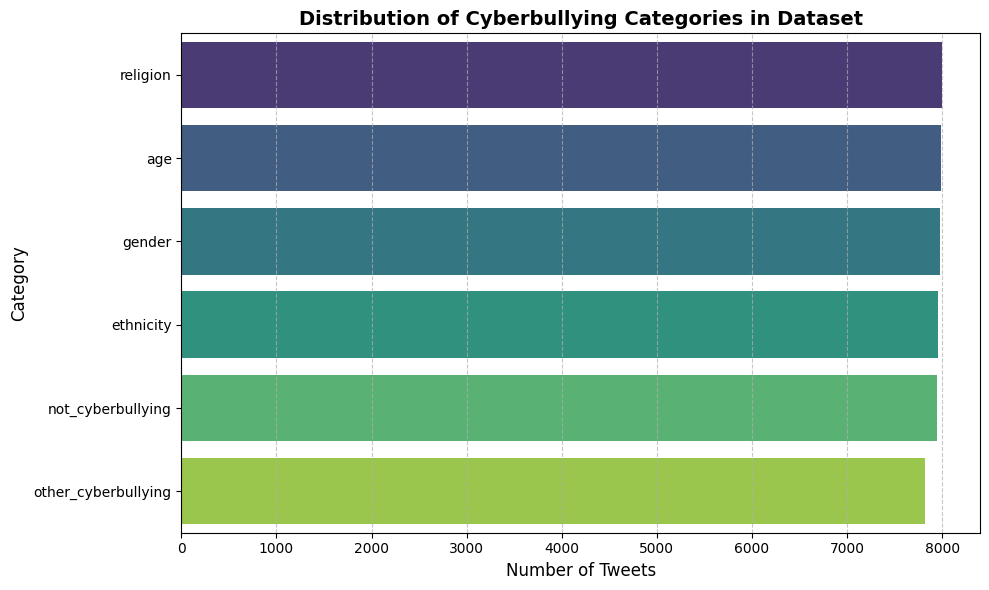

In [7]:
# Step 4: Display Category Distribution
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate counts for each category
category_counts = df['cyberbullying_type'].value_counts()
print("Category counts in dataset:")
print(category_counts)
print("-" * 50)

# 2. Plot the distribution
plt.figure(figsize=(10, 6))
sns.barplot(x=category_counts.values, y=category_counts.index, palette='viridis', hue=category_counts.index, legend=False)

# Customize chart labels
plt.title('Distribution of Cyberbullying Categories in Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Number of Tweets', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

In [8]:
# Step 5: Split the Dataset into Training and Testing Sets
from sklearn.model_selection import train_test_split

# 1. Define our features (X) and our target categories (y)
# We use 'cleaned_text' as our input and 'cyberbullying_type' as what we want to predict
X = df['cleaned_text']
y = df['cyberbullying_type']

# 2. Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Print the results of the split
print("Splitting complete!")
print(f"Total training samples (80%): {len(X_train)}")
print(f"Total testing samples (20%): {len(X_test)}")

Splitting complete!
Total training samples (80%): 38153
Total testing samples (20%): 9539


In [9]:
# Step 6: Convert Text to Numerical Vectors using TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Initialize the TF-IDF Vectorizer
# max_features=10000 means we only keep the top 10,000 most frequent/important words
vectorizer = TfidfVectorizer(max_features=10000, stop_words='english')

# 2. Learn the vocabulary from the training set and transform it into numerical vectors
print("Converting training text to TF-IDF vectors...")
X_train_tfidf = vectorizer.fit_transform(X_train)

# 3. Transform the testing set using the same vocabulary
print("Converting testing text to TF-IDF vectors...")
X_test_tfidf = vectorizer.transform(X_test)

print("-" * 50)
print("Vectorization complete!")
print(f"Training matrix shape: {X_train_tfidf.shape}")
print(f"Testing matrix shape: {X_test_tfidf.shape}")

Converting training text to TF-IDF vectors...
Converting testing text to TF-IDF vectors...
--------------------------------------------------
Vectorization complete!
Training matrix shape: (38153, 10000)
Testing matrix shape: (9539, 10000)


In [10]:
# Step 7: Train the Logistic Regression Model
from sklearn.linear_model import LogisticRegression

# 1. Initialize the Logistic Regression model
# We increase max_iter to 1000 to ensure the model converges on our large dataset
model = LogisticRegression(max_iter=1000, random_state=42)

# 2. Train (fit) the model on our vectorized training data
print("Training the Logistic Regression model... This might take up to a minute...")
model.fit(X_train_tfidf, y_train)

print("Model training complete!")

Training the Logistic Regression model... This might take up to a minute...
Model training complete!


Overall Model Accuracy: 81.57%
------------------------------------------------------------
Classification Report:
                     precision    recall  f1-score   support

                age       0.97      0.96      0.97      1598
          ethnicity       0.97      0.96      0.96      1592
             gender       0.91      0.83      0.87      1595
  not_cyberbullying       0.56      0.56      0.56      1589
other_cyberbullying       0.56      0.64      0.60      1565
           religion       0.96      0.94      0.95      1600

           accuracy                           0.82      9539
          macro avg       0.82      0.81      0.82      9539
       weighted avg       0.82      0.82      0.82      9539

------------------------------------------------------------


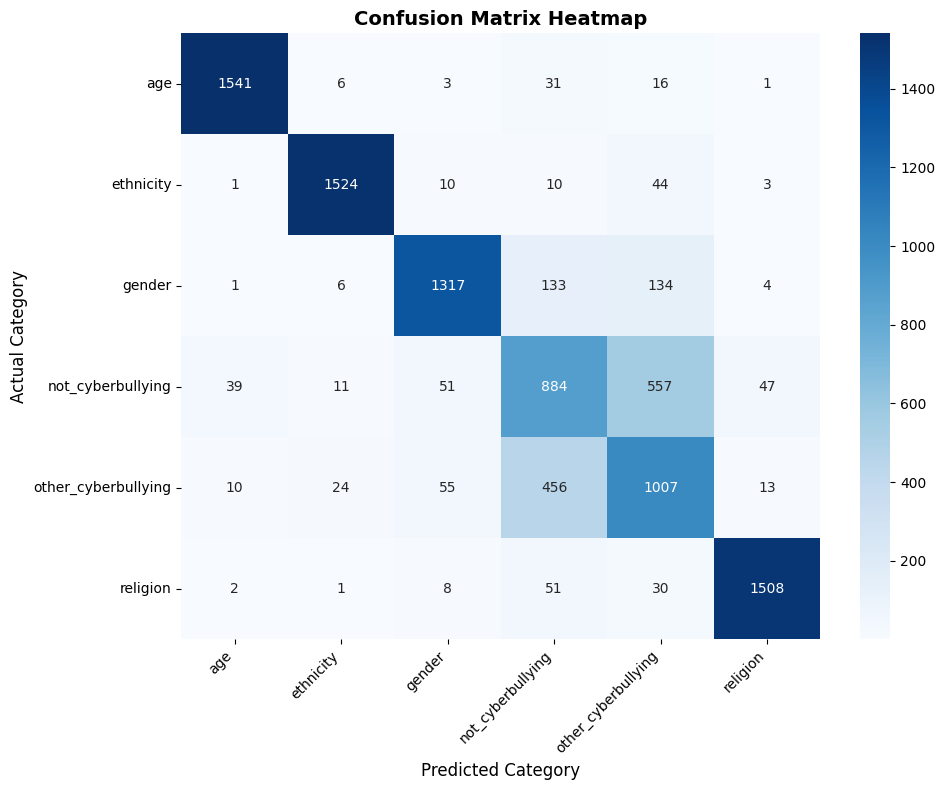

In [12]:
# Step 8: Evaluate the Model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Make predictions on the test set
y_pred = model.predict(X_test_tfidf)

# 2. Calculate and print accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Model Accuracy: {accuracy * 100:.2f}%")
print("-" * 60)

# 3. Print complete classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("-" * 60)

# 4. Compute and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.title('Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Category', fontsize=12)
plt.ylabel('Actual Category', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Step 9: Test the Model with Custom Example Tweets

def predict_tweet(custom_tweet):
    # 1. Clean the input text using our Step 3 function
    cleaned_input = clean_text(custom_tweet)

    # 2. Transform the text using our fitted TF-IDF vectorizer
    vectorized_input = vectorizer.transform([cleaned_input])

    # 3. Predict the category
    prediction = model.predict(vectorized_input)[0]

    # 4. Calculate prediction confidence (probability)
    probabilities = model.predict_proba(vectorized_input)[0]
    max_probability_index = np.argmax(probabilities)
    confidence = probabilities[max_probability_index] * 100

    return prediction, confidence

# --- Test the prediction function with sample sentences ---
samples = [
    "I am so excited to start college next month!",
    "You are way too old to be playing video games, go get a life!",
    "Nobody likes your religion, get out of our country!"
]

print("Custom Prediction Results:")
print("=" * 60)
for sentence in samples:
    predicted_class, confidence_score = predict_tweet(sentence)
    print(f"Tweet: \"{sentence}\"")
    print(f"Predicted Category: {predicted_class.upper()}")
    print(f"Confidence: {confidence_score:.2f}%")
    print("-" * 60)

In [13]:
# Step 10: Save and Download Model & Vectorizer
import joblib
from google.colab import files

# 1. Save the model and vectorizer as pickle (.pkl) files
joblib.dump(model, 'cyberbullying_model.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')
print("Files saved successfully as 'cyberbullying_model.pkl' and 'tfidf_vectorizer.pkl'.")
print("-" * 50)

# 2. Trigger automatic browser downloads for both files
print("Downloading files to your local computer...")
files.download('cyberbullying_model.pkl')
files.download('tfidf_vectorizer.pkl')

Files saved successfully as 'cyberbullying_model.pkl' and 'tfidf_vectorizer.pkl'.
--------------------------------------------------


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# Step 11: Build and Launch the Interactive Web App with Gradio
import gradio as gr
import numpy as np

def gradio_classify_tweet(tweet_text):
    # 1. Clean the incoming text using our established preprocessing
    cleaned = clean_text(tweet_text)

    # 2. Vectorize the text
    vectorized = vectorizer.transform([cleaned])

    # 3. Predict probabilities
    probabilities = model.predict_proba(vectorized)[0]

    # 4. Format outputs as a dictionary of label -> confidence score (for Gradio's Label component)
    classes = model.classes_
    results = {classes[i]: float(probabilities[i]) for i in range(len(classes))}

    return results

# Design a clean web interface using Gradio Blocks
# Note: Capitalized Markdown correctly and updated theme handling for newer Gradio versions
with gr.Blocks() as demo:
    gr.Markdown("# ☑ Cyberbullying Classification System")
    gr.Markdown(
        "This interactive web application uses our trained **TF-IDF & Logistic Regression Machine Learning Model** "
        "to automatically classify text into six distinct cyberbullying types."
    )

    with gr.Row():
        with gr.Column():
            input_text = gr.Textbox(
                label="Type or Paste Tweet/Text Here",
                placeholder="Type a message to analyze... (e.g., 'Nobody likes your religion!')",
                lines=4
            )
            submit_btn = gr.Button("Analyze Text", variant="primary")
            clear_btn = gr.Button("Clear")

        with gr.Column():
            output_labels = gr.Label(
                label="Classifier Confidence Scores",
                num_top_classes=3
            )

    # Set up actions
    submit_btn.click(fn=gradio_classify_tweet, inputs=input_text, outputs=output_labels)
    clear_btn.click(fn=lambda: "", inputs=None, outputs=input_text)

# Launch the live application with a shareable web URL
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d97c6c41eda0b5d1a8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
